FATURAMENTO TOTAL :

Abrindo, tratando e verificando dados.

In [27]:

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.pyplot import xticks
from numpy.ma.core import angle

url = "vendas.csv"

df_url = pd.read_csv(url, sep=';')
df_url['cidade_cliente'] = df_url['cidade_cliente'].fillna('Não Informada')
df_tratado = df_url.drop_duplicates().copy()
df_tratado['quantidade'] = df_tratado['quantidade'].abs()
nomes_vendedores = df_url.groupby("nome_vendedor").size()
nome_categorias = df_url.groupby("categoria_produto").size()
print ("-"*50)
print (nome_categorias)
print ("-"*50)
df_tratado['categoria_limpa'] = df_tratado['categoria_produto'].replace({
    'Informatica': 'Informática',
    'Eletronicos': 'Eletrônicos'
})
df_tratado['data_venda'] = pd.to_datetime(df_tratado['data_venda'], errors='coerce')
df_tratado = df_tratado.dropna(subset=['data_venda']).copy()
print (nomes_vendedores)
print ("-"*50)



--------------------------------------------------
categoria_produto
Acessórios      9941
Eletronicos       47
Eletrônicos    13335
Informatica       62
Informática    19915
Áudio           6700
dtype: int64
--------------------------------------------------
nome_vendedor
Ana Silva         3348
Bruno Costa       3236
Carlos Eduardo    3479
Diana Souza       3298
Eduardo Lima      3237
Fernanda Alves    3418
Gabriel Gomes     3328
Helena Rocha      3214
Igor Santos       3225
Julia Martins     3484
Kauan Vieira      3419
Larissa Mendes    3304
Marcos Paulo      3420
Natália Pires     3203
Otávio Borges     3387
dtype: int64
--------------------------------------------------


Calculei o faturamento bruto por item (quantidade X preço) e o líquido por categoria para entender a situação atual das vendas.

------------- RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS) -------------
		Faturamento Total Bruto:   R$ 117,627,401.80
		Total de Descontos:        R$ 7,325,877.70 (6.23%)
		Faturamento Total Líquido: R$ 110,301,524.10
----------------------------------------------------------------------


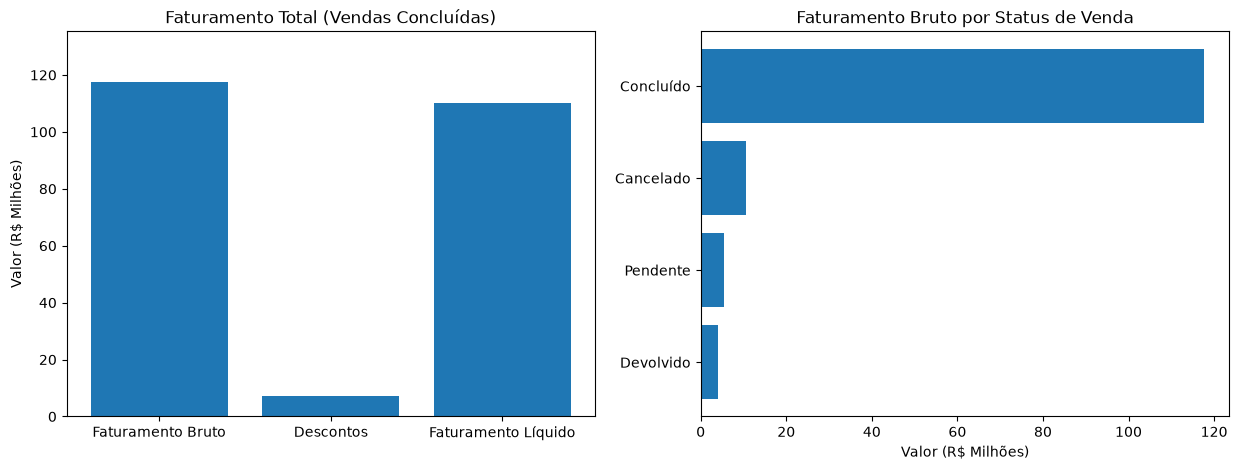

In [29]:
df_tratado['faturamento_bruto'] = df_tratado['quantidade'] * df_tratado['preco_unitario']
df_vendas_concluidas = df_tratado[df_tratado['status_venda'] == 'Concluído']

#calculando as categorias bruto, líquido e descontos
faturamento_total_bruto = df_vendas_concluidas['faturamento_bruto'].sum()
total_descontos = df_vendas_concluidas['desconto'].sum()
faturamento_total_liquido = df_vendas_concluidas['valor_total'].sum()

#criando nova variavel p ver a media de descontos que estão aplicando nas vendas.
taxa_desconto = (total_descontos / faturamento_total_bruto) * 100

#exibindo os dados das vendas
print("-" * 13, "RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS)", "-" * 13)
print(f"\t\tFaturamento Total Bruto:   R$ {faturamento_total_bruto:,.2f}")
print(f"\t\tTotal de Descontos:        R$ {total_descontos:,.2f} ({taxa_desconto:.2f}%)")
print(f"\t\tFaturamento Total Líquido: R$ {faturamento_total_liquido:,.2f}")
print("-"*70)

#criando 2 gráficos com subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

# inserindo nos gráficos as info ( dividido por 1mm pra formatar o valor.)
categorias = ['Faturamento Bruto', 'Descontos', 'Faturamento Líquido']
valores_milhoes = [
    faturamento_total_bruto / 1000000,
    total_descontos / 1000000,
    faturamento_total_liquido / 1000000
]

barras = axs[0].bar(categorias, valores_milhoes)
axs[0].set_title('Faturamento Total (Vendas Concluídas)')
axs[0].set_ylabel('Valor (R$ Milhões)')
axs[0].set_ylim(0, max(valores_milhoes) * 1.15)


resumo_status = df_tratado.groupby('status_venda')['faturamento_bruto'].sum().sort_values(ascending=True)
axs[1].barh(resumo_status.index, resumo_status.values / 1000000 )
axs[1].set_title('Faturamento Bruto por Status de Venda')
axs[1].set_xlabel('Valor (R$ Milhões)')



plt.show()

tirei o  VOLUME DE VENDAS : tops 10 itens mais vendidos


               nome_produto  quantidade
0      Teclado Mecânico RGB        4389
1            Monitor 27" 4K        4330
2      Smartphone Premium X        4279
3       Smartphone Básico Y        4266
4       Mouse Gamer 10k DPI        4262
5        Notebook Estudante        4221
6     Caixa de Som Portátil        4218
7        Notebook Ultra Pro        4179
8           Smart TV 55" 4K        4177
9  Fone de Ouvido Bluetooth        4172


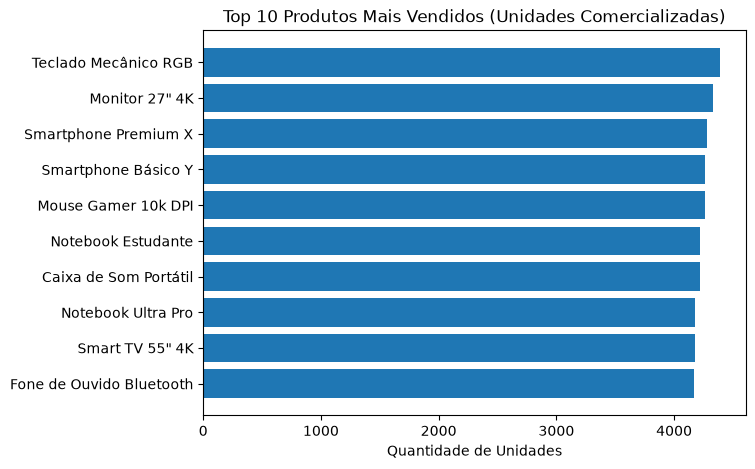

In [83]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']


#agrupando os produtos com groupby e somando as quantidades pra gerar o relatório das top 10
top10_produtos = (
    df_concluido.groupby('nome_produto')['quantidade'].sum().sort_values(ascending=False).head(10).reset_index()
)
print(top10_produtos)

#criando o gráfico e inserindo os dados

plt.figure(figsize=(7, 5))
dados_plot = top10_produtos.sort_values('quantidade', ascending=True)

plt.barh(dados_plot['nome_produto'], dados_plot['quantidade'])
plt.title('Top 10 Produtos Mais Vendidos (Unidades Comercializadas)')
plt.xlabel('Quantidade de Unidades')
plt.show()

------------- RESUMO DE FATURAMENTO CATEGORIAS -------------
		  categoria_limpa  valor_total  porcentagem participacao %
0     Informática  59324153.84                   53.783621
1     Eletrônicos  43549096.99                   39.481863
2      Acessórios   4477086.49                    4.058953
3           Áudio   2951186.78                    2.675563
----------------------------------------------------------------------


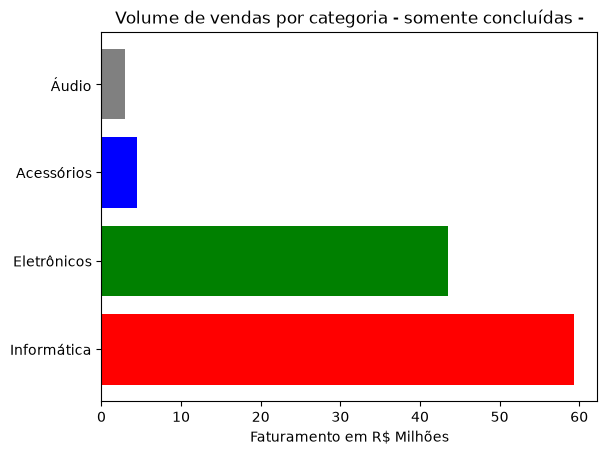

In [5]:
#filtrando e calculando
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído']

faturamento_categoria = (
    df_concluido.groupby('categoria_limpa')['valor_total'].sum().sort_values(ascending=False).reset_index()
)
faturamento_categoria['porcentagem participacao %'] = (faturamento_categoria['valor_total'] / faturamento_categoria['valor_total'].sum()) * 100
print("-" * 13, "RESUMO DE FATURAMENTO CATEGORIAS", "-" * 13)
print(f"\t\t{faturamento_categoria}")
print("-"*70)

#criando e adicionando dados
plt.figure()
barras = plt.barh(faturamento_categoria['categoria_limpa'], faturamento_categoria['valor_total'] / 1000000, color=['r', 'g', 'b', 'gray'])
plt.title('Volume de vendas por categoria - somente concluídas -')
plt.xlabel('Faturamento em R$ Milhões')
plt.show()

Aqui vamos explorar a evolução durante os meses para compreender melhor a sazonalidade de vendas durante o períodos de jan/21 e dez/23 para tomar melhores decisões de ação.

In [93]:
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído'].copy()
df_concluido['ano'] = df_concluido['data_venda'].dt.year

soma_anual = df_concluido.groupby('ano')['valor_total'].sum()
v2021 = soma_anual[2021]
v2022 = soma_anual[2022]
v2023 = soma_anual[2023]

dif_2022 = v2022 - v2021
pct_2022 = (dif_2022 / v2021) * 100
dif_2023 = v2023 - v2022
pct_2023 = (dif_2023 / v2022) * 100
print("-"*50)
print("Faturamento total entre os anos e as diferenças em relação ao ano anterior.")
print(f"2021: R$ {v2021:,.2f}")
print(f"2022: R$ {v2022:,.2f} | Diferença: R$ {dif_2022:,.2f} ({pct_2022:.2f}%)")
print(f"2023: R$ {v2023:,.2f} | Diferença: R$ {dif_2023:,.2f} ({pct_2023:.2f}%)")
print("-"*50)





--------------------------------------------------
Faturamento total entre os anos e as diferenças em relação ao ano anterior.
2021: R$ 36,814,175.96
2022: R$ 36,179,139.79 | Diferença: R$ -635,036.17 (-1.72%)
2023: R$ 37,308,208.35 | Diferença: R$ 1,129,068.56 (3.12%)
--------------------------------------------------


Evolução:     mes_ano  valor_total
11  2021-12   4179355.59
10  2021-11   3780032.03
22  2022-11   3709859.29
23  2022-12   3689253.01
31  2023-08   3425270.36
35  2023-12   3395337.25
24  2023-01   3354019.42
33  2023-10   3240568.53
28  2023-05   3236756.58
34  2023-11   3234472.33
27  2023-04   3133510.77
0   2021-01   3125678.08
12  2022-01   3113142.10
20  2022-09   3089908.08
19  2022-08   3088617.02
30  2023-07   3082527.12
7   2021-08   3081047.38
6   2021-07   3049079.62
16  2022-05   3042267.46
9   2021-10   3012053.99
14  2022-03   2979571.49
25  2023-02   2975020.40
17  2022-06   2962035.05
2   2021-03   2960942.41
4   2021-05   2957965.94
8   2021-09   2919834.13
29  2023-06   2851496.76
15  2022-04   2765731.75
3   2021-04   2728535.85
32  2023-09   2716135.63
26  2023-03   2663093.20
5   2021-06   2662660.06
13  2022-02   2632670.84
21  2022-10   2619553.05
18  2022-07   2486530.65
1   2021-02   2356990.88


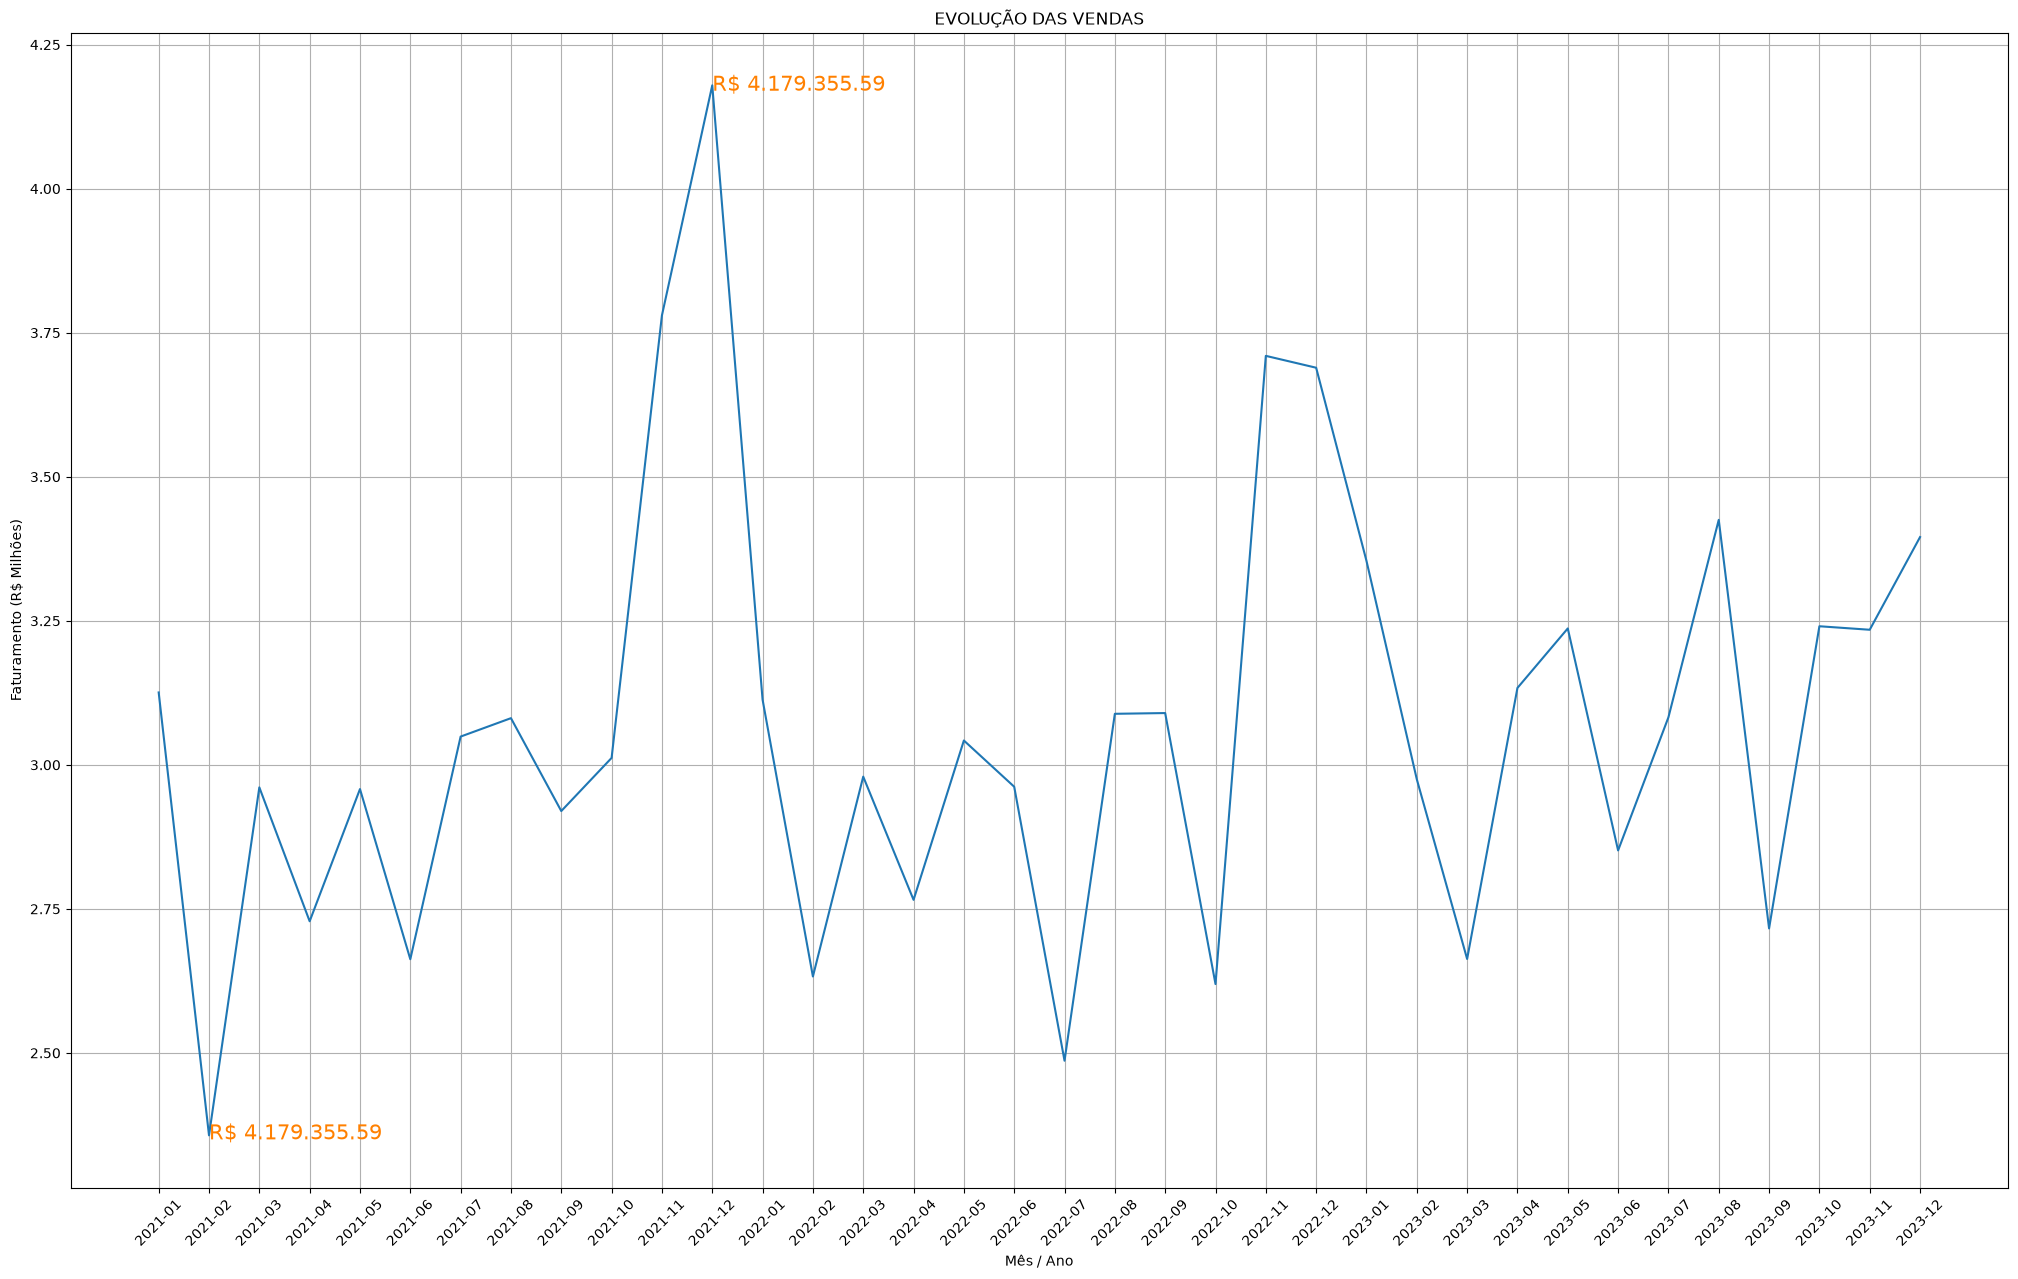

In [90]:

#filtrar datas e somar o faturamento
df_concluido = df_tratado[df_tratado['status_venda'] == 'Concluído'].copy()
df_concluido['mes_ano'] = df_concluido['data_venda'].astype(str).str.slice(0, 7)
evolucao = df_concluido.groupby('mes_ano')['valor_total'].sum().reset_index()

print("Evolução:", evolucao.sort_values('valor_total', ascending=False))


#criando e adicionando informações no gráfico
fig, grafico = plt.subplots(figsize=(25,15))
grafico.plot(evolucao['mes_ano'], evolucao['valor_total'] / 1000000)

grafico.set(xlabel='Mês / Ano',
       ylabel='Faturamento (R$ Milhões)',
       title='EVOLUÇÃO DAS VENDAS')

plt.text("2021-12", 4.17, "R$ 4.179.355.59", fontsize=15, color='#FF8000')
plt.text("2021-02", 2.35, "R$ 4.179.355.59", fontsize=15, color='#FF8000')


plt.xticks(rotation=45)
grafico.grid()
plt.show()